# 08b Detector calibration

The threshold in 08a was set on shuffled copies of each product's baseline year, and its 4.8% false-alarm rate was
measured on the same kind of copies. That number was always going to come out near 5%. Shuffled 4-week blocks also
throw away the yearly season. Here we build break-free series that keep the yearly season and longer runs of ups
and downs, and measure the false-alarm rate again, with the threshold left exactly as it was. Then we work out how
many products have a real shift once chance alarms are taken out.

The break-free series: take each product's weekly series after the ramp-up, split it with STL (period 52) into
trend, season and remainder, throw the trend away, and rebuild the series as the baseline mean plus the season plus
the remainder shuffled in 13-week blocks. There is no shift in it by construction. We make 20 per product.

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from break_detection import to_weekly
from calibration import (seasonal_null, deseasonalize, cusum_alarm, pelt_changepoints,
                         adjusted_share_ci, injection_trials)

SEED = 42
BURN_IN, REF_LEN, K = 8, 52, 1.0
N_NULL = 20
calib = pd.read_csv("../outputs/tables/break_calibration.csv").set_index('method')
H, PEN = float(calib.loc['CUSUM', 'value']), float(calib.loc['PELT', 'value'])
print(f"Frozen thresholds: CUSUM h = {H:.3f}, PELT penalty = {PEN:.2f}")

weekly, category = {}, {}
for cat in ['foods', 'hobbies', 'household']:
    df = pd.read_csv(f"../data/interim/{cat}_candidates.csv", parse_dates=['date'])
    for item, g in df.groupby('item_id'):
        weekly[item] = to_weekly(g.sort_values('date')).to_numpy()
        category[item] = cat.upper()
print(len(weekly), "items")

Frozen thresholds: CUSUM h = 14.385, PELT penalty = 31.03


726 items


## False alarms on realistic break-free series

If real series raise an alarm at rate O and break-free ones at rate F, the share with a real shift is estimated as
(O - F) / (1 - F), with a bootstrap confidence interval over products.

In [2]:
rng = np.random.default_rng(SEED)
rows, nulls = [], {}
for item, v in weekly.items():
    series, kind = seasonal_null(v, BURN_IN, REF_LEN, n_series=N_NULL, rng=rng)
    nulls[item] = series
    rows.append({
        'item_id': item, 'category': category[item], 'null_kind': kind, 'n_weeks': len(v),
        'cusum_real': cusum_alarm(v, H, K, BURN_IN, REF_LEN)[0] is not None,
        'pelt_real': len(pelt_changepoints(v, PEN, BURN_IN, REF_LEN)) > 0,
        'cusum_far': np.mean([cusum_alarm(s, H, K, BURN_IN, REF_LEN)[0] is not None for s in series]),
        'pelt_far': np.mean([len(pelt_changepoints(s, PEN, BURN_IN, REF_LEN)) > 0 for s in series]),
    })
item_level = pd.DataFrame(rows)
item_level.to_csv("../outputs/tables/calibration_item_level.csv", index=False)
print(item_level['null_kind'].value_counts().to_string())

null_kind
seasonal_residual_bootstrap    718
reference_bootstrap              8


In [3]:
out = []
main = item_level[item_level['null_kind'] == 'seasonal_residual_bootstrap']
groups = [('ALL (seasonal null)', main)] + [(c, g) for c, g in main.groupby('category')]
short = item_level[item_level['null_kind'] != 'seasonal_residual_bootstrap']
if len(short):
    groups.append(('short series (reference-window null)', short))
for label, g in groups:
    for method in ['cusum', 'pelt']:
        r = adjusted_share_ci(g[f'{method}_real'], g[f'{method}_far'], seed=SEED)
        out.append({'group': label, 'method': method.upper(), 'n_null_series': len(g) * N_NULL, **r})
null_rates = pd.DataFrame(out)
null_rates.to_csv("../outputs/tables/calibration_null_rates.csv", index=False)
pd.set_option('display.width', 200)
print(null_rates.round(4).to_string(index=False))

                               group method  n_null_series  n_items  observed    far  adjusted  ci_low  ci_high
                 ALL (seasonal null)  CUSUM          14360      718    0.6783 0.1186    0.6350  0.5975   0.6721
                 ALL (seasonal null)   PELT          14360      718    0.8175 0.1607    0.7826  0.7494   0.8164
                               FOODS  CUSUM           6680      334    0.7006 0.1326    0.6548  0.5995   0.7099
                               FOODS   PELT           6680      334    0.8323 0.1734    0.7972  0.7494   0.8421
                             HOBBIES  CUSUM           2120      106    0.6415 0.1151    0.5949  0.4923   0.6930
                             HOBBIES   PELT           2120      106    0.8019 0.1538    0.7659  0.6734   0.8487
                           HOUSEHOLD  CUSUM           5560      278    0.6655 0.1031    0.6270  0.5655   0.6870
                           HOUSEHOLD   PELT           5560      278    0.8058 0.1480    0.7720  0.7176  

## What if we take the season out first?

A check we ran out of curiosity: subtract each product's STL seasonal part and run the same detector. The season
comes from the whole series, so this could never be used for forecasting.

In [4]:
rows = []
for item, v in weekly.items():
    d = deseasonalize(v, BURN_IN)
    if d is None:
        continue
    rows.append({'item_id': item, 'category': category[item],
                 'cusum_raw': cusum_alarm(v, H, K, BURN_IN, REF_LEN)[0] is not None,
                 'cusum_deseason': cusum_alarm(d, H, K, BURN_IN, REF_LEN)[0] is not None,
                 'pelt_raw': len(pelt_changepoints(v, PEN, BURN_IN, REF_LEN)) > 0,
                 'pelt_deseason': len(pelt_changepoints(d, PEN, BURN_IN, REF_LEN)) > 0})
des = pd.DataFrame(rows)
summary = []
for label, g in [('ALL', des)] + list(des.groupby('category')):
    for m in ['cusum', 'pelt']:
        summary.append({'group': label, 'method': m.upper(), 'n_items': len(g),
                        'rate_raw': g[f'{m}_raw'].mean(), 'rate_deseasonalized': g[f'{m}_deseason'].mean(),
                        'flag_lost': (g[f'{m}_raw'] & ~g[f'{m}_deseason']).mean(),
                        'flag_gained': (~g[f'{m}_raw'] & g[f'{m}_deseason']).mean()})
des_summary = pd.DataFrame(summary)
des_summary.to_csv("../outputs/tables/calibration_deseasonalized.csv", index=False)
print(des_summary.round(4).to_string(index=False))

    group method  n_items  rate_raw  rate_deseasonalized  flag_lost  flag_gained
      ALL  CUSUM      718    0.6783               0.9735     0.0070       0.3022
      ALL   PELT      718    0.8175               0.9833     0.0014       0.1671
    FOODS  CUSUM      334    0.7006               0.9641     0.0120       0.2754
    FOODS   PELT      334    0.8323               0.9760     0.0030       0.1467
  HOBBIES  CUSUM      106    0.6415               0.9811     0.0000       0.3396
  HOBBIES   PELT      106    0.8019               0.9811     0.0000       0.1792
HOUSEHOLD  CUSUM      278    0.6655               0.9820     0.0036       0.3201
HOUSEHOLD   PELT      278    0.8058               0.9928     0.0000       0.1871


## Steps and drifts of known size

We plant a shift in the break-free series, as a sudden step or as a slow drift that reaches full size after 26
weeks, at a random date. Because the hosts have no shift of their own, we know the right answer every time.

In [5]:
SIZES = [0.0, 0.05, 0.10, 0.20, 0.30]
rng = np.random.default_rng(SEED + 1)
parts = []
for item, v in weekly.items():
    ref_mean = v[BURN_IN:BURN_IN + REF_LEN].mean()
    t = injection_trials(nulls[item][:5], ref_mean, H, PEN, SIZES, k=K, burn_in=BURN_IN, ref_len=REF_LEN, rng=rng)
    if len(t):
        t['item_id'] = item
        parts.append(t)
trials = pd.concat(parts, ignore_index=True)
n_excl = int(trials['excluded'].sum())
ok = trials[~trials['excluded']]
n_hosts = ok[ok['size'] == 0].shape[0]
print(f"Hosts used: {n_hosts}; excluded because the host alarmed before the injection date: {n_excl}")

inj = ok.groupby(['shape', 'size']).agg(
    n_trials=('cusum_detected', 'size'),
    cusum_power=('cusum_detected', 'mean'),
    cusum_power_26wk=('cusum_within_26', 'mean'),
    cusum_median_delay_wks=('cusum_delay', 'median'),
    cusum_correct_sign=('cusum_sign_ok', 'mean'),
    pelt_hit=('pelt_hit', 'mean')).reset_index()
inj.to_csv("../outputs/tables/calibration_injection.csv", index=False)
print(inj.round(4).to_string(index=False))

Hosts used: 3397; excluded because the host alarmed before the injection date: 193


shape  size  n_trials cusum_power cusum_power_26wk  cusum_median_delay_wks cusum_correct_sign  pelt_hit
drift  0.05      3397    0.075361          0.01884                    54.0           0.049455  0.042979
drift  0.10      3397    0.090374         0.019429                    54.0           0.069767  0.064763
drift  0.20      3397    0.169856         0.022078                    55.0           0.156314  0.221077
drift  0.30      3397    0.322343         0.036503                    50.0           0.311746  0.447159
 none  0.00      3397    0.070062          0.01884                    49.5           0.038269  0.016191
 step  0.05      3397    0.075066         0.018251                    54.0           0.050044  0.016485
 step  0.10      3397    0.092729         0.020901                    53.0             0.0733  0.029143
 step  0.20      3397    0.183397         0.047395                    45.0           0.171328  0.173388
 step  0.30      3397    0.350898         0.117457              

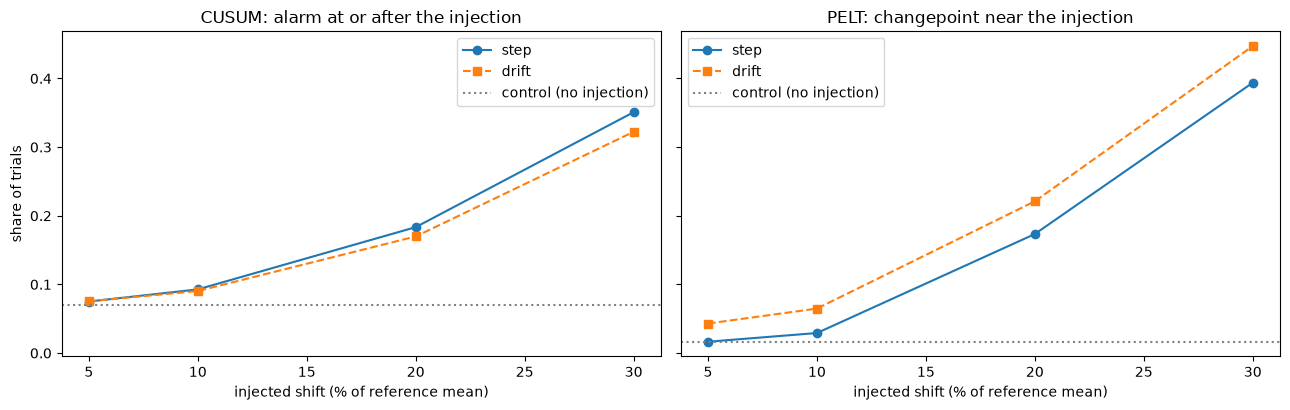

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
ctrl = inj[inj['shape'] == 'none'].iloc[0]
for ax, col, title in [(axes[0], 'cusum_power', 'CUSUM: alarm at or after the injection'),
                       (axes[1], 'pelt_hit', 'PELT: changepoint near the injection')]:
    for shape, style in [('step', '-o'), ('drift', '--s')]:
        d = inj[inj['shape'] == shape]
        ax.plot(100 * d['size'], d[col], style, label=shape)
    ax.axhline(ctrl[col], color='grey', ls=':', label='control (no injection)')
    ax.set(title=title, xlabel='injected shift (% of reference mean)')
    ax.legend()
axes[0].set_ylabel('share of trials')
plt.tight_layout()
plt.savefig("../outputs/figures/calibration_injection_power.png", dpi=120)
plt.show()

## The four things we wrote down to check

In [7]:
allrow = null_rates[(null_rates['group'] == 'ALL (seasonal null)') & (null_rates['method'] == 'CUSUM')].iloc[0]
step = inj[inj['shape'] == 'step'].set_index('size')
drift = inj[inj['shape'] == 'drift'].set_index('size')
c = ctrl['cusum_power']
verdicts = [
    ('H1.1 CUSUM FAR on the new null is above 5%', allrow['far'] > 0.05, f"FAR = {allrow['far']:.4f}"),
    ('H1.2 adjusted share is below the observed share', allrow['adjusted'] < allrow['observed'],
     f"adjusted {allrow['adjusted']:.4f} (CI {allrow['ci_low']:.4f} to {allrow['ci_high']:.4f}) vs observed {allrow['observed']:.4f}"),
    ('H1.3 power at 5% and 10% within 10 points of control (steps and drifts)',
     all(abs(x.loc[s, 'cusum_power'] - c) < 0.10 for x in (step, drift) for s in (0.05, 0.10)),
     f"control {c:.4f}; step 5%/10% {step.loc[0.05, 'cusum_power']:.4f}/{step.loc[0.10, 'cusum_power']:.4f}; "
     f"drift 5%/10% {drift.loc[0.05, 'cusum_power']:.4f}/{drift.loc[0.10, 'cusum_power']:.4f}"),
    ('H1.4 drifts are detected later than steps at every size',
     all(drift.loc[s, 'cusum_median_delay_wks'] > step.loc[s, 'cusum_median_delay_wks'] for s in (0.05, 0.10, 0.20, 0.30)),
     '; '.join(f"{int(100*s)}%: step {step.loc[s, 'cusum_median_delay_wks']:.0f} vs drift {drift.loc[s, 'cusum_median_delay_wks']:.0f} wks"
               for s in (0.05, 0.10, 0.20, 0.30))),
]
hyp = pd.DataFrame(verdicts, columns=['hypothesis', 'supported', 'evidence'])
hyp.to_csv("../outputs/tables/calibration_hypotheses.csv", index=False)
for h_, s_, e_ in verdicts:
    print(f"{'SUPPORTED' if s_ else 'NOT SUPPORTED'}: {h_}\n    {e_}")

SUPPORTED: H1.1 CUSUM FAR on the new null is above 5%
    FAR = 0.1186
SUPPORTED: H1.2 adjusted share is below the observed share
    adjusted 0.6350 (CI 0.5975 to 0.6721) vs observed 0.6783
SUPPORTED: H1.3 power at 5% and 10% within 10 points of control (steps and drifts)
    control 0.0701; step 5%/10% 0.0751/0.0927; drift 5%/10% 0.0754/0.0904
NOT SUPPORTED: H1.4 drifts are detected later than steps at every size
    5%: step 54 vs drift 54 wks; 10%: step 53 vs drift 54 wks; 20%: step 45 vs drift 55 wks; 30%: step 36 vs drift 50 wks


## What we found

On realistic break-free series the detector is noisier than we thought: 11.9% of them raise a false alarm with
CUSUM, and 16.1% with PELT, not the 4.8% from 08a. Taking that into account, 63.5% of products have a real shift
(95% CI 59.8% to 67.2%), down from 67.8% flagged. PELT gives 78.3% (74.9% to 81.6%). So shifts are common, but some
alarms are chance: about 4% of all products, or roughly 6% of the alarms, would be flagged even without a real shift.

The detector is coarse. A sudden shift of 5% or 10% is caught no more often than nothing at all (7.0% for the
control), a 20% step only 18% of the time, and a 30% step 35% of the time. We expected slow drifts to be caught later
than sudden steps at every size; that only held for 20% and 30%, so one of our four expectations was wrong.

The deseasonalised run flagged 97% of products. That does not mean 97% have shifts: removing the season shrinks the
baseline spread, so the same threshold becomes much easier to cross. We did not build a matching break-free set for
that case, so we report the number only as a warning about how sensitive the detector is to seasonality.

## What comes next

`08c_high_confidence_breaks` keeps only the shifts that are large, confirmed by PELT, and lasting.

In [8]:
# files this notebook wrote
from pathlib import Path
ROOT = Path('..').resolve()
written = [ROOT / p for p in ['outputs/tables/calibration_item_level.csv', 'outputs/tables/calibration_null_rates.csv', 'outputs/tables/calibration_deseasonalized.csv', 'outputs/tables/calibration_injection.csv', 'outputs/tables/calibration_hypotheses.csv', 'outputs/figures/calibration_injection_power.png']]
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\tables\calibration_item_level.csv 54 KB
outputs\tables\calibration_null_rates.csv 1 KB
outputs\tables\calibration_deseasonalized.csv 1 KB
outputs\tables\calibration_injection.csv 1 KB
outputs\tables\calibration_hypotheses.csv 1 KB
outputs\figures\calibration_injection_power.png 69 KB
